## EN3160 Assignment 03: Neural Networks
### Bandara W.D.A.C. - 230082G
Github Repo : [https://github.com/Achintha-Bandara/CVNN.git](https://github.com/Achintha-Bandara/CVNN.git)

Using device: cuda
GPU: NVIDIA GeForce MX550


100.0%
C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Epoch 1/20, Loss: 0.976900
Epoch 2/20, Loss: 0.949804
Epoch 3/20, Loss: 0.936071
Epoch 4/20, Loss: 0.927523
Epoch 5/20, Loss: 0.921587
Epoch 6/20, Loss: 0.917185
Epoch 7/20, Loss: 0.913772
Epoch 8/20, Loss: 0.911046
Epoch 9/20, Loss: 0.908817
Epoch 10/20, Loss: 0.906966
Epoch 11/20, Loss: 0.905406
Epoch 12/20, Loss: 0.904080
Epoch 13/20, Loss: 0.902942
Epoch 14/20, Loss: 0.901959
Epoch 15/20, Loss: 0.901105
Epoch 16/20, Loss: 0.900360
Epoch 17/20, Loss: 0.899708
Epoch 18/20, Loss: 0.899135
Epoch 19/20, Loss: 0.898630
Epoch 20/20, Loss: 0.898183


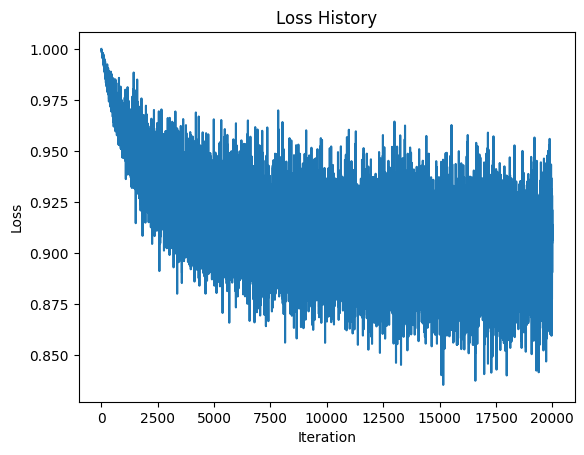

Training accuracy: 32.20%
Test accuracy: 32.38%


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 0. Select Compute Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases on the selected device
w = torch.randn(Din, K, device=device) * std
b = torch.zeros(K, device=device)

# Hyperparameters
iterations = 20
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Ntr = inputs.shape[0]

        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (Mean Squared Error with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        with torch.no_grad():
            w -= lr * dw
            b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader):.6f}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 0. Select Compute Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 256

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

# 2. Define Network Parameters
Din = 3 * 32 * 32   # Input size
H = 100             # Hidden layer nodes
K = 10              # Output classes

# Initialize weights and biases
# Xavier initialization
w1 = torch.randn(Din, H, device=device) * (2.0 / (Din + H))**0.5
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * (2.0 / (H + K))**0.5
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10
lr = 0.1
lr_decay = 0.9

loss_history = []

# 3. Training Loop
for t in range(epochs):
    running_loss = torch.zeros((), device=device)

    for inputs, labels in trainloader:

        # Move data to GPU
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        N = inputs.shape[0]

        # Flatten input images
        x = inputs.view(N, -1)

        # One-hot encoded labels
        y_true = nn.functional.one_hot(labels, K).float()

        # Forward propagation
        z1 = x.mm(w1) + b1
        h = torch.sigmoid(z1)

        z2 = h.mm(w2) + b2

        # Cross-entropy loss
        log_probs = nn.functional.log_softmax(z2, dim=1)
        loss = -torch.sum(y_true * log_probs) / N

        running_loss += loss.detach()

        # Backpropagation: output layer
        probs = torch.softmax(z2, dim=1)

        dz2 = (probs - y_true) / N
        dw2 = h.t().mm(dz2)
        db2 = dz2.sum(dim=0)

        # Backpropagation: hidden layer
        dh = dz2.mm(w2.t())
        dz1 = dh * h * (1.0 - h)

        dw1 = x.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Update parameters
        with torch.no_grad():
            w2 -= lr * dw2
            b2 -= lr * db2

            w1 -= lr * dw1
            b1 -= lr * db1

    # Record and print epoch loss
    epoch_loss = (running_loss / len(trainloader)).item()
    loss_history.append(epoch_loss)

    print(
        f"Epoch {t + 1}/{epochs}, "
        f"Loss: {epoch_loss:.4f}"
    )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(range(1, epochs + 1), loss_history, marker='o')
plt.title("Training Loss History")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for inputs, labels in trainloader:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        N = inputs.shape[0]
        x = inputs.view(N, -1)

        # Forward propagation
        h = torch.sigmoid(x.mm(w1) + b1)
        scores = h.mm(w2) + b2

        predicted = torch.argmax(scores, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for inputs, labels in testloader:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        N = inputs.shape[0]
        x = inputs.view(N, -1)

        # Forward propagation
        h = torch.sigmoid(x.mm(w1) + b1)
        scores = h.mm(w2) + b2

        predicted = torch.argmax(scores, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")